# ITER free-boundary plasma equilibrium (2D axisymmetric)

This notebook computes the free-boundary equilibrium of the ITER 15 MA reference plasma, following
`examples/ITER_2D_fine2` (the refined linear mesh), and looks inside every step of the computation. It is the starting point of every plasma
evolution (see the next tutorial).

**The problem.** In an axisymmetric plasma the poloidal flux per radian $\psi(R,Z) = R A_\varphi$ obeys the
Grad-Shafranov equation

$$
\Delta^*\psi \;=\; R\frac{\partial}{\partial R}\Big(\frac{1}{R}\frac{\partial\psi}{\partial R}\Big)
  + \frac{\partial^2\psi}{\partial Z^2} \;=\; -\mu_0 R\,J_\varphi,
\qquad
J_\varphi = R\,p'(\psi) + \frac{F F'(\psi)}{\mu_0 R}\;\text{in the plasma},
$$

with $J_\varphi$ the imposed current density in the coils and zero in vacuum. It is *free boundary*: the plasma
is the region inside the last closed flux surface, which is itself part of the solution. pyTEC3D does not solve
the Grad-Shafranov equation as such: the field equation is the finite-element magnetostatic problem of the
element library ($\nabla\times\nu\nabla\times A = J$, which in axisymmetry is the same operator), and the
`Algorithm` class wraps it in a **Picard iteration** on the plasma current density:

1. from $\psi$, find the magnetic axis (maximum of $\psi$), the X point (saddle) and the limiter point (the wall
   point of largest $\psi$); the larger of $\psi_X$, $\psi_{lim}$ is the boundary flux $\psi_b$, and the cells
   inside it connected to the axis are the plasma;
2. set $J_\varphi = \lambda\,(1-\bar\psi^{\alpha_m})^{\alpha_n}\big(\beta\,R/R_0 + (1-\beta)\,R_0/R\big)$ in the
   plasma, with $\bar\psi = (\psi-\psi_{axis})/(\psi_b-\psi_{axis})$ and $\lambda$ scaling the total to $I_p$;
3. correct the currents of the control coils so that the poloidal field at the target axis vanishes (position
   control);
4. solve the field with the new currents; stop when $\psi$ no longer changes.

What we do: look at the machine model, set the coil currents and the algorithm parameters (and check where the
control parameters come from), run the iterations one by one, then analyse the converged equilibrium: flux map,
separatrix, current density, pressure and toroidal-field profiles, global quantities, and a 3D view. The run takes
about 10 s. Theory: *Theory - Plasma equilibrium and evolution*; options: *User manual - Plasma algorithm*.

In [1]:
import os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # warnings ("No loads" at every voltage-driven step...) stay in the job log

CASE = Path("../../examples/ITER_2D_fine2").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_ITER_2D_fine2_"))
for name in ("ITER_2D_fine2.vtu", "model_data.json"):
    shutil.copy(CASE / name, WORK / name)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

import contextlib, io
def quietly():
    """Keep the report tables that the solver prints (run provenance, run summary) out of the notebook: they are in
    the job log <model name>.log of the working folder."""
    return contextlib.redirect_stdout(io.StringIO())

import json, time
from pytec3d import Algorithm, ConvergenceError, element_library

from matplotlib.collections import PolyCollection
from matplotlib.tri import Triangulation

def polygons(grid, mask=None):
    """The (R, Z) polygons of the cells of a 2D grid (all of them, or those where mask is True)."""
    g = pv.wrap(grid)
    points, conn, offset = g.points[:, :2], g.cell_connectivity, g.cell_offsets
    ids = np.arange(g.n_cells) if mask is None else np.flatnonzero(mask)
    return [points[conn[offset[i]:offset[i + 1]]] for i in ids]

def fill(ax, grid, mask, values=None, **kwargs):
    """Draw cells: one colour (facecolor=...) or coloured by the cell values (cmap=..., clim=...)."""
    collection = PolyCollection(polygons(grid, mask), **kwargs)
    if values is not None:
        collection.set_array(np.asarray(values)[mask])
    ax.add_collection(collection)
    return collection

def triangulation(grid):
    """The grid as matplotlib triangles over its points (for contours of point arrays such as PSI)."""
    t = pv.wrap(grid).triangulate()
    return Triangulation(t.points[:, 0], t.points[:, 1], t.cells.reshape(-1, 4)[:, 1:])

def frame(ax, r=(0.0, 13.0), z=(-9.0, 9.0)):
    ax.set_xlim(*r); ax.set_ylim(*z); ax.set_aspect("equal"); ax.set_xlabel("R [m]"); ax.set_ylabel("Z [m]")

working in a temporary folder: pytec3d_ITER_2D_fine2_xk5rs6jb


## The machine

`ITER_2D_fine2.vtu` is the poloidal cross-section (x = R, y = Z) of the whole machine in a 100 m x 200 m half-plane of
air: the six central-solenoid modules CS3U ... CS3L, the six poloidal-field coils PF1 ... PF6, the vacuum chamber
(where the plasma can be) and the **passive structures**: the double-wall vacuum vessel and the in-vessel supports,
massive steel conductors. Every component is a cell array with value 1 on its cells. The model data gives two TYPE
ids: 21 air (`NON_CONDUCTING`) and 23 for all the rest (`STRANDED_CONDUCTOR`, a region where the current density `Js`
is imposed). The equilibrium is a sequence of static solves, so no eddy current flows and the conductivities play no
role. In the evolution (next tutorials) the passive structures become **solid conductors** (`SOLID_CONDUCTOR`): the
massive conductors in which the plasma motion induces eddy currents.

In [2]:
solver = Solver(log_file="ITER_2D_fine2.log")
algorithm = Algorithm(solver)
solver.read_model("ITER_2D_fine2.vtu")
solver.model.read_json("model_data.json")
mesh = solver.model.mesh
grid = pv.wrap(mesh)

components = ["CS3U", "CS2U", "CS1U", "CS1L", "CS2L", "CS3L", "PFC_1", "PFC_2", "PFC_3", "PFC_4", "PFC_5", "PFC_6",
              "VACUUM_CHAMBER", "PASSIVE_STRUCTURES"]
area = grid.cell_data["cell_volume"]            # in 2D the cell size is its area [m^2]
centroid = grid.cell_data["cell_centroids"]
print(f"{grid.n_points} points, {grid.n_cells} cells; TYPE ids", np.unique(grid.cell_data["TYPE"]))
print(f"{'component':>18} {'cells':>6} {'area [m2]':>10} {'R [m]':>6} {'Z [m]':>6}")
for name in components:
    on = grid.cell_data[name] == 1
    r, z = (centroid[on, :2] * area[on, None]).sum(axis=0) / area[on].sum()
    print(f"{name:>18} {on.sum():6d} {area[on].sum():10.4f} {r:6.2f} {z:6.2f}")

17928 points, 17876 cells; TYPE ids [21 23 24]
         component  cells  area [m2]  R [m]  Z [m]
              CS3U     50     1.5561   1.70   5.44
              CS2U     50     1.5561   1.70   3.26
              CS1U     50     1.5561   1.70   1.09
              CS1L     50     1.5561   1.70  -1.07
              CS2L     50     1.5561   1.70  -3.25
              CS3L     50     1.5561   1.70  -5.42
             PFC_1     25     0.9438   3.94   7.57
             PFC_2     15     0.4145   8.29   6.54
             PFC_3     25     0.6641  11.99   3.28
             PFC_4     25     0.6087  11.96  -2.23
             PFC_5     25     0.7750   8.39  -6.73
             PFC_6     25     1.7266   4.33  -7.47
    VACUUM_CHAMBER   7876    28.6027   5.92   0.47
PASSIVE_STRUCTURES   1624     1.3747   5.79   0.16


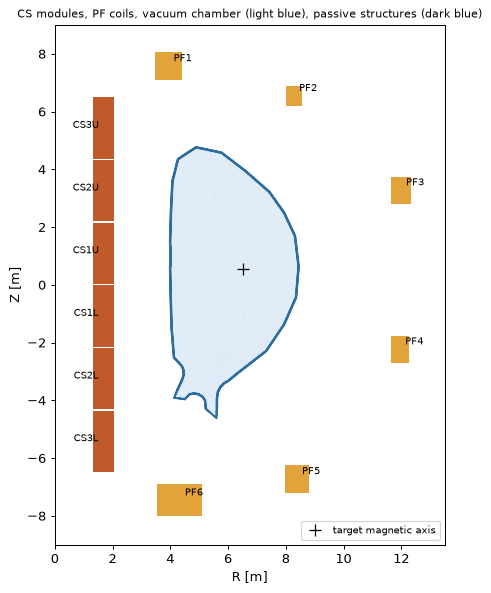

In [3]:
fig, ax = plt.subplots(figsize=(6, 7.5))
fill(ax, mesh, grid.cell_data["VACUUM_CHAMBER"] == 1, facecolor="#dbe9f6", edgecolor="none")
fill(ax, mesh, grid.cell_data["PASSIVE_STRUCTURES"] == 1, facecolor="#2c6e9e", edgecolor="#2c6e9e", linewidth=0.6)
for name in components[:6]:
    fill(ax, mesh, grid.cell_data[name] == 1, facecolor="#c05a2a", edgecolor="none")
for name in components[6:12]:
    fill(ax, mesh, grid.cell_data[name] == 1, facecolor="#e3a33b", edgecolor="none")
for name in components[:12]:
    on = grid.cell_data[name] == 1
    r, z = (centroid[on, :2] * area[on, None]).sum(axis=0) / area[on].sum()
    ax.annotate(name.replace("PFC_", "PF"), (r, z), xytext=(4, 4) if r > 2 else (-4, 0),
                textcoords="offset points", fontsize=8, ha="left" if r > 2 else "right")
ax.plot(6.52136102486433, 0.536537145137914, "k+", ms=10, label="target magnetic axis")
frame(ax, r=(0, 13.5)); ax.legend(loc="lower right", fontsize=8)
ax.plot([], [], color="#2c6e9e", lw=4, label="passive structures (solid conductors)")
ax.set_title("CS modules, PF coils, vacuum chamber (light blue), passive structures (dark blue)", fontsize=9)
plt.show()

The model data rows (`model_data.json`): `option1` is the domain of each TYPE, `option2 = 1` the vector potential
`A_z` as unknown, `option3 = 1` axisymmetry. Rows 24 and 25 (solid conductor, stranded coil) are not used by any
cell here: they serve the evolution cases, which share the same file layout.

In [4]:
data = json.load(open("model_data.json"))
domains = dict(enumerate(element_library.domains()))
for tid, row in data["element_types"].items():
    print(f"TYPE {tid}: {domains.get(row['option1'], row['option1']):26s} {row}")

TYPE 21: NON_CONDUCTING             {'element_type': 0, 'option1': 0, 'option2': 1, 'option3': 1}
TYPE 23: STRANDED_CONDUCTOR         {'element_type': 0, 'option1': 3, 'option2': 1, 'option3': 1}
TYPE 24: SOLID_CONDUCTOR            {'element_type': 0, 'option1': 5, 'option2': 1, 'option3': 1}
TYPE 25: STRANDED_COIL              {'element_type': 0, 'option1': 6, 'option2': 1, 'option3': 1}


## Boundary condition and analysis type

$A_z = 0$ on the external boundary: on the axis R = 0 (where $\psi = R A_\varphi = 0$ anyway) and far away
(the field of a current loop decays fast, so 100 m is far enough). Every Picard iteration is a magnetostatic solve.
The model is loaded into a solver session once: the arrays (`Js` in particular) can be changed between solves, and
the factorized matrix is reused at every iteration, since the step does not change.

In [5]:
selection.select_all(mesh)
selection.nsel_ext(mesh)
selection.set_value_on_selection(mesh, "_A", 0.0, 2)

solver.time_step.update(time=1.0, transient_effects=False, theta=1.0)
with quietly():
    solver.load_model_into_solver()

## Position control: computing the `b*_value` coefficients

At every iteration the algorithm measures the poloidal field $(B_R, B_Z)$ at the target position of the magnetic
axis and computes a *radial* and a *vertical* correction current, $I_{rad}$ and $I_{ver}$, that would cancel it:

$$
\begin{pmatrix} b_{rad,x} & b_{ver,x}\\ b_{rad,y} & b_{ver,y}\end{pmatrix}
\begin{pmatrix} I_{rad}\\ I_{ver}\end{pmatrix} = -\begin{pmatrix} B_R\\ B_Z\end{pmatrix}.
$$

The four coefficients are the field at the target of a **unit correction current**: a radial correction of 1 A is
+1 A in PF2 and -1 A in PF5 (the two outer coils, which push the plasma in and out), a vertical one +1 A in PF3 and in
PF4 (which push it up and down). They are properties of the coils and of the mesh only, so we compute them before the
equilibrium, with two magnetostatic solves of the model: 1 MA of radial (then vertical) correction current in the
coils and no other current, and the flux density read at the target point (the nodal field ``B``, interpolated at
the point).

In [6]:
target = (6.52136102486433, 0.536537145137914, 0.0)
coil_area = {"PFC_1": 0.94375190, "PFC_2": 0.41453946, "PFC_3": 0.66413094, "PFC_4": 0.60871516,
             "PFC_5": 0.77496250, "PFC_6": 1.72659250, "CS": 1.55608}
unit_corrections = {"radial": {"PFC_2": +1.0, "PFC_5": -1.0}, "vertical": {"PFC_3": +1.0, "PFC_4": +1.0}}
probe = pv.PolyData(np.array([target]))
js = meshes.array_values(mesh, "Js", "elem")
b_unit = {}
for name, coils in unit_corrections.items():
    js[:] = 0.0
    for coil, sign in coils.items():
        js[grid.cell_data[coil] == 1, 2] = sign * 1e6 / coil_area[coil]      # 1 MA through the coil cross-section
    meshes.get_array(mesh, "Js", "elem").Modified()
    with quietly():
        solver.solve()
    sampled = probe.sample(pv.wrap(mesh))                                    # interpolate the nodal B at the target
    b_unit[name] = sampled.point_data["B"][0, :2] / 1e6                       # T per A of correction current

macro = {"radial": (-3.873415861e-08, 5.313857037e-09), "vertical": (1.822467692e-10, 1.133287835e-07)}
print(f"{'':10s} {'computed':>24s} {'test macro':>24s}")
for name, label in (("radial", "rad"), ("vertical", "ver")):
    for k, axis in enumerate("xy"):
        print(f"b{label}{axis}_value  {b_unit[name][k]:+24.4e} {macro[name][k]:+24.4e}")

                           computed               test macro
bradx_value               -3.8720e-08              -3.8734e-08
brady_value               +5.3209e-09              +5.3139e-09
bverx_value               +2.2954e-10              +1.8225e-10
bvery_value               +1.1317e-07              +1.1333e-07


The computed coefficients agree with the values written in the test macro, which were obtained the same way. In the
test the control coils have the gains +-0.5 (`control_coils` below), while the coefficients are those of unit gains:
the algorithm computes the correction current that would cancel the field, and the coils receive half of it. The
gains 0.5 are an **under-relaxation of 0.5** of the position control, which damps the coupling between the moving
plasma and its correction from one iteration to the next.

Note also that the correction is recomputed at every iteration from the field of the current state and *replaces*
the previous one (the coils keep their scenario current as the base): the control is proportional, so a residual
field, and a small offset of the axis from the target, remain at convergence. We will measure them below.

## Coil currents and the initial guess

The coil currents of the scenario point (ampere-turns of each coil) become current densities `Js_z = I / a` on
the cells of each coil. The plasma current is not known yet: the first solve uses 15 MA spread uniformly over the
whole vacuum chamber, a rough guess that only has to give a flux with an axis and an X point inside the chamber.

In [7]:
coil_current = {"CS3U": -4.8204e06, "CS2U": -4.0480e06, "CS1U": -2.0804e07, "CS1L": -2.0804e07,
                "CS2L": -1.0297e07, "CS3L": 5.3012e06,
                "PFC_1": 5.7325e06, "PFC_2": -2.8834e06, "PFC_3": -5.8084e06, "PFC_4": -4.7762e06,
                "PFC_5": -7.8133e06, "PFC_6": 1.6941e07}
plasma_current, chamber_area = 15e6, 28.6027095

selection.select_all(mesh)
selection.set_value_on_selection(mesh, "Js", 0.0, location="elem")       # forget the response solves above
for coil, current in coil_current.items():
    selection.select(mesh, coil, 1, location="elem")
    selection.set_value_on_selection(mesh, "Js", current / coil_area["CS" if coil.startswith("CS") else coil], 2,
                                     location="elem")
selection.select(mesh, "VACUUM_CHAMBER", 1, location="elem")
selection.set_value_on_selection(mesh, "Js", plasma_current / chamber_area, 2, location="elem")

js = meshes.array_values(mesh, "Js", "elem")
for name in ("COILS", "VACUUM_CHAMBER"):
    on = grid.cell_data[name] == 1
    print(f"total current in {name}: {(js[on, 2] * area[on]).sum() / 1e6:+.2f} MA(-turns)")

total current in COILS: -54.08 MA(-turns)
total current in VACUUM_CHAMBER: +15.00 MA(-turns)


## Algorithm parameters

| parameter | value | meaning |
|---|---|---|
| `target_central_axis_x/y` | 6.521, 0.537 m | where the position control wants the magnetic axis |
| `R0` | 6.2 m | major radius of the current profile |
| `plasma_current` | 15 MA | $I_p$, imposed through $\lambda$ |
| `beta_p` | 0.682 | $\beta$ of the profile: the share of the pressure term $\beta R/R_0$ |
| `alpha_mp`, `alpha_np` | 1.0001, 0.83197 | shape of the profile $(1-\bar\psi^{\alpha_m})^{\alpha_n}$ |
| `AF0` | $5.3\times6.2$ T m | vacuum $F = R B_\varphi$: 5.3 T at 6.2 m (used for $F$ and the poloidal currents) |
| `control_coils`, `b*_value` | gains +-0.5, coefficients computed above | position control |
| `tolerance_value` | 1e-4 Wb/rad | convergence: $\max\lvert\psi_k-\psi_{k-1}\rvert$ |
| `max_picard_iterations` | 70 | the solve raises `ConvergenceError` beyond |

In [8]:
algorithm.input_parameters.update(
    target_central_axis_x=target[0], target_central_axis_y=target[1], target_central_axis_z=0.0,
    R0=6.2, plasma_current=plasma_current, beta_p=0.68216, alpha_mp=1.0001, alpha_np=0.83197, AF0=5.3 * 6.2,
    control_coils=[{"component": "PFC_2", "radial_gain": 0.5, "vertical_gain": 0.0},
                   {"component": "PFC_3", "radial_gain": 0.0, "vertical_gain": 0.5},
                   {"component": "PFC_4", "radial_gain": 0.0, "vertical_gain": 0.5},
                   {"component": "PFC_5", "radial_gain": -0.5, "vertical_gain": 0.0}],
    bradx_value=b_unit["radial"][0], brady_value=b_unit["radial"][1],          # computed above
    bverx_value=b_unit["vertical"][0], bvery_value=b_unit["vertical"][1],
    tolerance_value=1e-4, max_picard_iterations=70)

## The Picard iterations, one at a time

`algorithm.equilibrium_solve()` runs the whole loop and returns when $\psi$ has converged, as the test macro does.
To watch the iterations we call it with `max_picard_iterations = 1`: each call does one iteration and raises
`ConvergenceError` until the last one; the state of the algorithm (previous flux, control-coil currents) is kept
between calls, so the sequence is the same as one call with 70 iterations. After each iteration we keep the flux of
the vacuum chamber (`algorithm.vacuum_chamber_mesh`, the mesh on which the algorithm works) and the status.

In [9]:
algorithm.input_parameters["max_picard_iterations"] = 1
history, started = [], time.perf_counter()
for iteration in range(1, 71):
    try:
        with quietly():
            converged = algorithm.equilibrium_solve()
    except ConvergenceError:
        converged = False
    chamber = algorithm.vacuum_chamber_mesh
    history.append({"psi": meshes.array_values(chamber, "PSI", "node").copy(), **algorithm.status})
    if converged:
        break
status = algorithm.status
print(f"converged at iteration {iteration} in {time.perf_counter() - started:.1f} s")
offset = np.subtract(status["magnetic_axis"][:2], target[:2])
print(f"axis - target = ({offset[0] * 100:+.1f}, {offset[1] * 100:+.1f}) cm, residual field at the target "
      f"(B_R, B_Z) = ({status['b_target_axis'][0] * 1e3:+.2f}, {status['b_target_axis'][1] * 1e3:+.2f}) mT")
for key in ("separatrix_configuration", "magnetic_axis", "x_point", "limiter_point", "psi_magnetic_axis",
            "psi_min", "plasma_element_count", "plasma_current_scaling_lambda",
            "radial_correction_current", "vertical_correction_current", "flux_norm"):
    value = status[key]
    print(f"  {key:32s}", tuple(round(v, 4) for v in value[:2]) if isinstance(value, tuple) else value)

converged at iteration 31 in 5.3 s
axis - target = (+1.7, +3.2) cm, residual field at the target (B_R, B_Z) = (-0.47, +4.42) mT
  separatrix_configuration         X-point
  magnetic_axis                    (6.5384, 0.5688)
  x_point                          (5.1413, -3.3708)
  limiter_point                    (5.6469, -3.6513)
  psi_magnetic_axis                12.853375292151764
  psi_min                          -0.0050445840481112255
  plasma_element_count             5779
  plasma_current_scaling_lambda    1463109.8482759432
  radial_correction_current        -12325.924176482205
  vertical_correction_current      -38490.87970106487
  flux_norm                        8.014127390620907e-05


The status after every iteration is also appended to `output/ITER_2D_fine2_iteration_diagnostics.csv` in the working
folder (one row per iteration, the points split in x/y/z columns), which is what you would look at after a batch
run:

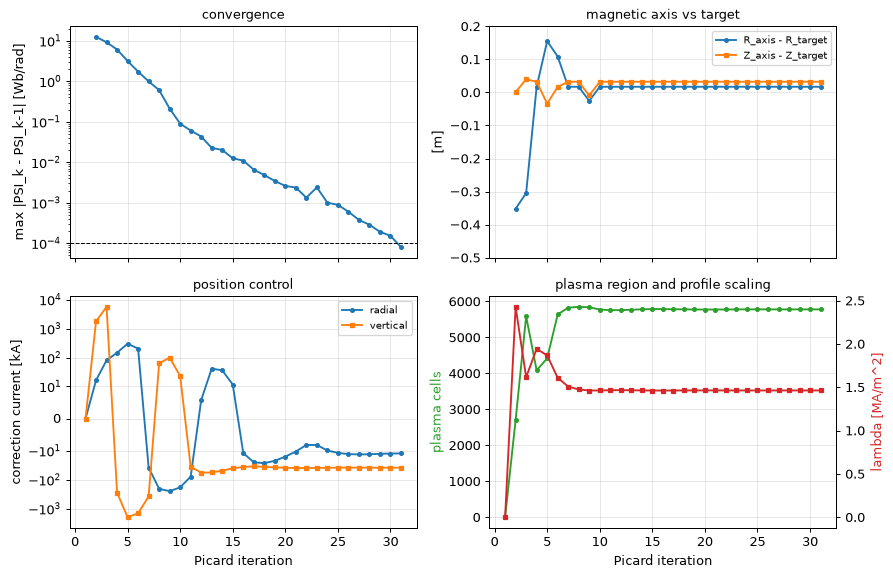

In [10]:
diag = np.genfromtxt("output/ITER_2D_fine2_iteration_diagnostics.csv", delimiter=",", names=True, dtype=None,
                     encoding="utf-8")
it = np.arange(1, len(diag) + 1)
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
ax = axes[0, 0]
ax.semilogy(it[1:], diag["flux_metric"][1:], "o-", ms=3); ax.axhline(1e-4, color="k", ls="--", lw=0.8)
ax.set_ylabel("max |PSI_k - PSI_k-1| [Wb/rad]"); ax.set_title("convergence", fontsize=10)
ax = axes[0, 1]
ax.plot(it[1:], diag["magnetic_axis_x"][1:] - target[0], "o-", ms=3, label="R_axis - R_target")
ax.plot(it[1:], diag["magnetic_axis_y"][1:] - target[1], "s-", ms=3, label="Z_axis - Z_target")
ax.set_ylabel("[m]"); ax.set_ylim(-0.5, 0.2); ax.legend(fontsize=8); ax.set_title("magnetic axis vs target", fontsize=10)
ax = axes[1, 0]
ax.plot(it, diag["radial_correction_current"] / 1e3, "o-", ms=3, label="radial")
ax.plot(it, diag["vertical_correction_current"] / 1e3, "s-", ms=3, label="vertical")
ax.set_yscale("symlog", linthresh=10); ax.set_ylabel("correction current [kA]"); ax.legend(fontsize=8); ax.set_title("position control", fontsize=10)
ax = axes[1, 1]
ax.plot(it, diag["plasma_element_count"], "o-", ms=3, color="C2"); ax.set_ylabel("plasma cells", color="C2")
ax2 = ax.twinx(); ax2.plot(it, diag["plasma_current_scaling_lambda"] / 1e6, "s-", ms=3, color="C3")
ax2.set_ylabel("lambda [MA/m^2]", color="C3"); ax.set_title("plasma region and profile scaling", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("Picard iteration")
for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

How to read it:

* the first iteration only solves the initial guess (no plasma region yet: zero cells, no correction); from the
  second on, the plasma takes its shape: too small at first, then too large and touching the wall (limited, in
  some of the early iterations, while the control pulls it back), then diverted again for good (picture below);
* the flux change falls roughly geometrically: the Picard iteration is a fixed-point iteration, linearly
  convergent; its rate is set by how strongly the plasma shape reacts to its own current;
* the correction currents swing by several MA in the first iterations, while the plasma forms, then settle to a
  steady correction of a few tens of kA: being proportional to the residual field, they do not go to zero, and the
  axis stops a few cm from the target (the magnetic axis is also a mesh node: it moves in steps of the node
  spacing);
* $\lambda$ settles when the plasma region stops changing.

If an equilibrium does not converge, these curves are the first thing to look at: an axis that oscillates around
the target asks for smaller gains (more relaxation); a large offset from the target, for larger gains; a plasma region that keeps changing size, for a better initial
guess or coil currents closer to the scenario.

### The plasma boundary during the iterations

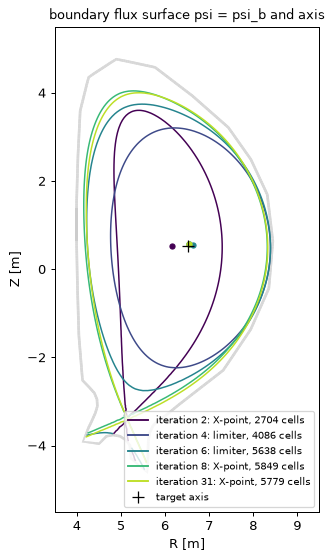

In [11]:
chamber = algorithm.vacuum_chamber_mesh
chamber_tri = triangulation(chamber)
fig, ax = plt.subplots(figsize=(5.5, 7))
fill(ax, mesh, grid.cell_data["PASSIVE_STRUCTURES"] == 1, facecolor="0.8", edgecolor="none")
shown = [2, 4, 6, 8, len(history)]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(shown)))
for k, color in zip(shown, colors):
    h = history[k - 1]            # the status of iteration k: boundary found on the flux of iteration k - 1
    ax.tricontour(chamber_tri, history[k - 2]["psi"], levels=[h["psi_min"]], colors=[color], linewidths=1.2, linestyles="solid")
    ax.plot(*h["magnetic_axis"][:2], "o", color=color, ms=4)
    ax.plot([], [], color=color, label=f"iteration {k}: {h['separatrix_configuration']}, {h['plasma_element_count']} cells")
ax.plot(*target[:2], "k+", ms=10, label="target axis")
frame(ax, r=(3.5, 9.5), z=(-5.5, 5.5)); ax.legend(fontsize=8, loc="lower right")
ax.set_title("boundary flux surface psi = psi_b and axis", fontsize=10)
plt.show()

## The converged equilibrium

### Flux surfaces, separatrix and plasma region

The flux of the whole model is in the point array `PSI` of the solver mesh ($\psi = R A_z$, Wb/rad). The plasma
(`PLASMA = 1` cells of the vacuum chamber) is bounded by the separatrix $\psi = \psi_b = \psi_X$ since the
configuration is diverted (`X-point`): the X point is below the plasma, and its two legs reach the divertor. The
limiter point, the wall point of largest flux, has $\psi_{lim} < \psi_X$: the plasma does not touch the wall.

psi_axis = 12.8534, psi_b = psi_X = -0.00504, psi_limiter = -0.4539 Wb/rad


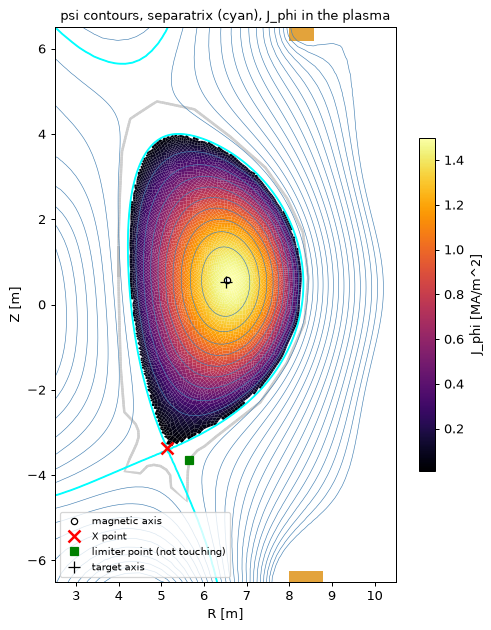

In [12]:
psi = meshes.array_values(mesh, "PSI", "node")
psi_axis, psi_b = status["psi_magnetic_axis"], status["psi_min"]
plasma = meshes.array_values(chamber, "PLASMA", "elem") == 1
jphi = meshes.array_values(chamber, "Js", "elem")[:, 2]

fig, ax = plt.subplots(figsize=(6.5, 8))
fill(ax, mesh, grid.cell_data["PASSIVE_STRUCTURES"] == 1, facecolor="0.75", edgecolor="none")
for name in components[:12]:
    fill(ax, mesh, grid.cell_data[name] == 1, facecolor="#e3a33b", edgecolor="none")
pc = fill(ax, chamber, plasma, jphi / 1e6, cmap="inferno", edgecolor="none")
fig.colorbar(pc, ax=ax, shrink=0.6, label="J_phi [MA/m^2]")
levels = psi_b + (psi_axis - psi_b) * np.linspace(-1.5, 1.0, 26)
ax.tricontour(triangulation(mesh), psi, levels=np.sort(levels), colors="steelblue", linewidths=0.5,
              linestyles="solid")
ax.tricontour(triangulation(mesh), psi, levels=[psi_b], colors="cyan", linewidths=1.5, linestyles="solid")
ax.plot(*status["magnetic_axis"][:2], "wo", ms=5, mec="k", label="magnetic axis")
ax.plot(*status["x_point"][:2], "rx", ms=9, mew=2, label="X point")
ax.plot(*status["limiter_point"][:2], "gs", ms=6, label="limiter point (not touching)")
ax.plot(*target[:2], "k+", ms=10, label="target axis")
frame(ax, r=(2.5, 10.5), z=(-6.5, 6.5)); ax.legend(fontsize=8, loc="lower left")
ax.set_title(f"psi contours, separatrix (cyan), J_phi in the plasma", fontsize=10)
plt.show()
print(f"psi_axis = {psi_axis:.4f}, psi_b = psi_X = {psi_b:.5f}, psi_limiter = {status['last_psi_limiter']:.4f} Wb/rad")

### Current density across the plasma

On the midplane through the axis, $J_\varphi$ is the product of the flux profile $(1-\bar\psi^{\alpha_m})^{\alpha_n}$,
which vanishes at the boundary, and of $\beta R/R_0 + (1-\beta)R_0/R$, which shifts the peak outwards for large
$\beta$ (the pressure term grows with R). The same profile also gives the poloidal current density
$\mathbf J_p = F'(\psi)\,\mathbf B_p$, in `Js_x`, `Js_y` (the current that flows along the flux surfaces in the
poloidal plane, linked to the toroidal field change $F(\psi)$ inside the plasma).

I_p = sum J_phi a = 15.000 MA over 5779 cells


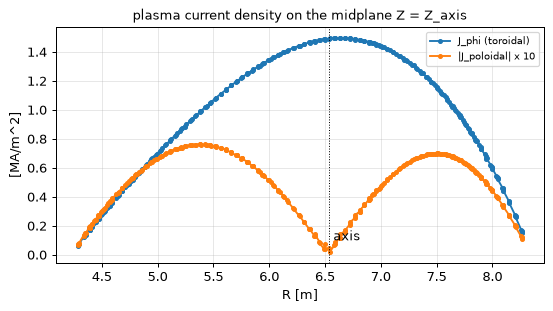

In [13]:
cc = meshes.array_values(chamber, meshes.CENTROIDS_ARRAY, "elem")
js_chamber = meshes.array_values(chamber, "Js", "elem")
band = plasma & (np.abs(cc[:, 1] - status["magnetic_axis"][1]) < 0.12)
order = np.argsort(cc[band, 0])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(cc[band, 0][order], js_chamber[band, 2][order] / 1e6, ".-", label="J_phi (toroidal)")
ax.plot(cc[band, 0][order], np.linalg.norm(js_chamber[band, :2], axis=1)[order] / 1e6 * 10, ".-",
        label="|J_poloidal| x 10")
ax.axvline(status["magnetic_axis"][0], color="k", lw=0.8, ls=":"); ax.text(status["magnetic_axis"][0], 0.1, " axis")
ax.set_xlabel("R [m]"); ax.set_ylabel("[MA/m^2]"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("plasma current density on the midplane Z = Z_axis", fontsize=10); plt.show()
cs = meshes.array_values(chamber, meshes.SIZES_ARRAY, "elem")
print(f"I_p = sum J_phi a = {(js_chamber[plasma, 2] * cs[plasma]).sum() / 1e6:.3f} MA over {plasma.sum()} cells")

### Pressure and toroidal-field function

Comparing the profile with $J_\varphi = R\,p' + FF'/(\mu_0 R)$ gives the two flux functions of the equilibrium:

$$
p'(\psi) = \frac{\lambda\beta}{R_0}\,g(\bar\psi), \qquad FF'(\psi) = \mu_0\lambda(1-\beta)R_0\,g(\bar\psi), \qquad
g = (1-\bar\psi^{\alpha_m})^{\alpha_n}.
$$

Integrating from the boundary ($p = 0$, $F = F_0$ = `AF0`), with $d\psi = (\psi_b - \psi_{axis})\,d\bar\psi$:

$$
p(\bar\psi) = \frac{\lambda\beta}{R_0}(\psi_{axis}-\psi_b)\int_{\bar\psi}^1 g\,ds, \qquad
F^2(\bar\psi) = F_0^2 + 2\mu_0\lambda(1-\beta)R_0(\psi_{axis}-\psi_b)\int_{\bar\psi}^1 g\,ds .
$$

The algorithm uses the same $F$ for the poloidal currents. From $p$ we get the stored thermal energy and the
poloidal beta $\beta_p = 2\mu_0\langle p\rangle / \bar B_p^2$, with $\bar B_p = \mu_0 I_p / L$ and $L$ the length
of the separatrix.

plasma volume 837 m^3, cross-section 21.8 m^2, separatrix length 18.38 m
p(axis) = 1.13 MPa, <p> = 323 kPa, W_th = 3/2 <p> V = 405 MJ
mean poloidal field 1.025 T -> beta_p = 2 mu0 <p> / Bp^2 = 0.771 (profile beta = 0.68216)
F on axis 33.625 T m vs F0 = 32.860 T m: the plasma is paramagnetic


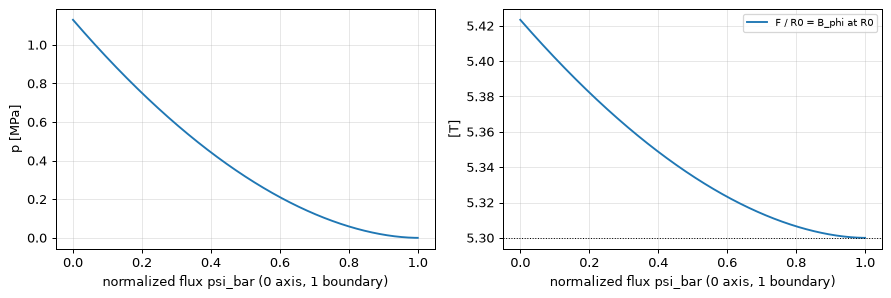

In [14]:
p = algorithm.input_parameters
lam, beta, r0, am, an, f0 = (status["plasma_current_scaling_lambda"], p["beta_p"], p["R0"], p["alpha_mp"],
                             p["alpha_np"], p["AF0"])
mu0 = 4e-7 * np.pi
s = np.linspace(0.0, 1.0, 2001)
g = np.maximum(1.0 - s**am, 0.0) ** an
tail = np.concatenate(([0.0], np.cumsum(0.5 * (g[1:] + g[:-1]) * np.diff(s))))
tail = tail[-1] - tail                                                       # int_s^1 g
pressure = lam * beta / r0 * (psi_axis - psi_b) * tail
F = np.sqrt(f0**2 + 2 * mu0 * lam * (1 - beta) * r0 * (psi_axis - psi_b) * tail)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(s, pressure / 1e6); axes[0].set_ylabel("p [MPa]")
axes[1].plot(s, F / r0, label="F / R0 = B_phi at R0"); axes[1].axhline(f0 / r0, color="k", ls=":", lw=0.8)
axes[1].set_ylabel("[T]"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("normalized flux psi_bar (0 axis, 1 boundary)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# global quantities over the plasma cells (volume element 2 pi R dA)
psi_bar = np.clip((meshes.array_values(chamber, "PSIe", "elem") - psi_axis) / (psi_b - psi_axis), 0, 1)
dv = 2 * np.pi * cc[:, 0] * cs
volume = dv[plasma].sum()
p_mean = (np.interp(psi_bar, s, pressure) * dv)[plasma].sum() / volume
scratch = plt.figure()                                  # the separatrix as a polyline, from a contour
contour = scratch.gca().tricontour(chamber_tri, history[-1]["psi"], levels=[psi_b + 1e-4 * (psi_axis - psi_b)])
length = max(np.linalg.norm(np.diff(seg, axis=0), axis=1).sum() for seg in contour.allsegs[0]); plt.close(scratch)
bp = mu0 * p["plasma_current"] / length
print(f"plasma volume {volume:.0f} m^3, cross-section {cs[plasma].sum():.1f} m^2, separatrix length {length:.2f} m")
print(f"p(axis) = {pressure[0] / 1e6:.2f} MPa, <p> = {p_mean / 1e3:.0f} kPa, W_th = 3/2 <p> V = {1.5 * p_mean * volume / 1e6:.0f} MJ")
print(f"mean poloidal field {bp:.3f} T -> beta_p = 2 mu0 <p> / Bp^2 = {2 * mu0 * p_mean / bp**2:.3f} (profile beta = {beta})")
print(f"F on axis {F[0]:.3f} T m vs F0 = {f0:.3f} T m: the plasma is {'para' if F[0] > f0 else 'dia'}magnetic")

The numbers are those of the ITER reference plasma: about 830 m$^3$, a central pressure around 1 MPa, some 400 MJ
of thermal energy. Note that the profile parameter `beta_p` is *not* exactly the poloidal beta of the result:
it fixes the share of the $R/R_0$ term in the current density, while $\beta_p$ also depends on the shape of the
plasma and on the profile exponents. To match a given $\beta_p$ one adjusts the parameter (an outer iteration).

### The current density of the output

The solver writes the total current density of the cells in `Jt`. In a stranded conductor it is the imposed `Js`,
evaluated at every output from the current loads: after the Picard iterations `Jt` of the plasma cells holds the
converged plasma current density, like `Js`:

In [15]:
jt = meshes.array_values(mesh, "Jt", "elem")[:, 2]
on = meshes.array_values(mesh, "PLASMA", "elem") == 1
js_solver = meshes.array_values(mesh, "Js", "elem")[:, 2]
print(f"over the PLASMA cells of the solver mesh: sum Js a = {(js_solver * area)[on].sum() / 1e6:.2f} MA, "
      f"sum Jt a = {(jt * area)[on].sum() / 1e6:.2f} MA")

over the PLASMA cells of the solver mesh: sum Js a = 15.00 MA, sum Jt a = 15.00 MA


## A 3D view

The plasma and the coils revolved by 270 degrees about the vertical axis: the cut faces show $J_\varphi$ in the
plasma and the flux surfaces.

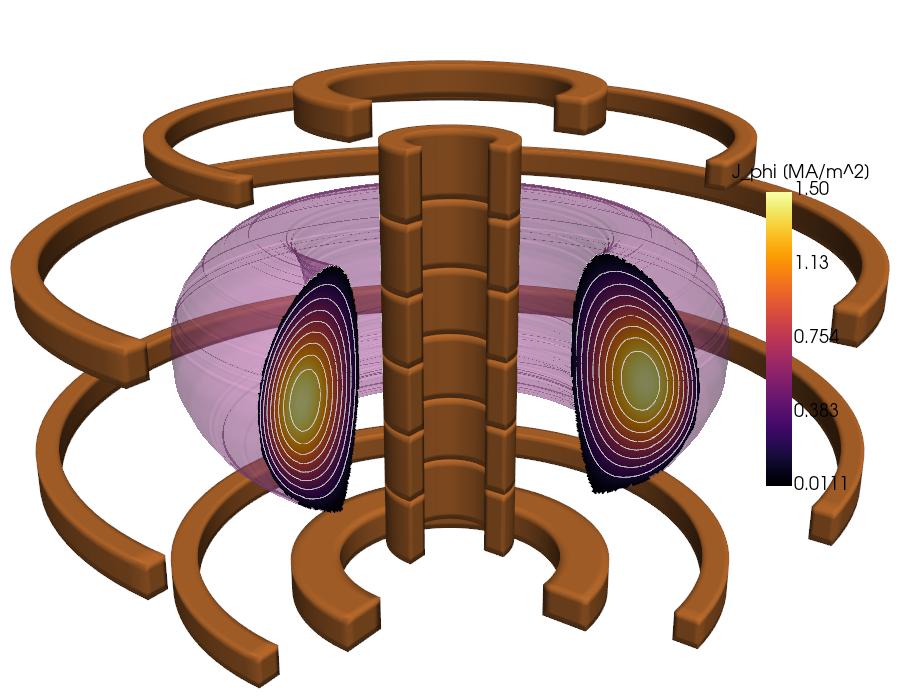

In [16]:
plasma_cells = pv.wrap(chamber).threshold(value=(1, 1), scalars="PLASMA").extract_surface(algorithm=None)
plasma_cells.cell_data["J_phi [MA/m^2]"] = plasma_cells.cell_data["Js"][:, 2] / 1e6
outline = plasma_cells.extract_feature_edges(boundary_edges=True, feature_edges=False, manifold_edges=False,
                                             non_manifold_edges=False)
shell = outline.extrude_rotate(resolution=90, angle=270, rotation_axis=(0, 1, 0), capping=False)
pl = pv.Plotter(window_size=(900, 700))
pl.add_mesh(shell, color="orchid", opacity=0.35, smooth_shading=True)
for cut in (plasma_cells, plasma_cells.rotate_y(270, point=(0, 0, 0))):
    pl.add_mesh(cut, scalars="J_phi [MA/m^2]", cmap="inferno",
                scalar_bar_args={"vertical": True, "position_x": 0.85, "position_y": 0.3})
    pl.add_mesh(cut.cell_data_to_point_data().contour(10, scalars="PSIe"), color="white", line_width=1)
for name in components[:12]:
    coil = grid.threshold(value=(1, 1), scalars=name).extract_surface(algorithm=None)
    pl.add_mesh(coil.extrude_rotate(resolution=90, angle=270, rotation_axis=(0, 1, 0), capping=True),
                color="#c87533", smooth_shading=True)
pl.camera_position = [(22, 14, 30), (0, 0, 0), (0, 1, 0)]
pl.show()

## Save the result

`write_output()` writes the solver mesh with all the arrays (A, PSI, Js of the plasma and the coils, PLASMA, B...)
as `output/ITER_2D_fine2_out_<n>.vtu`, where `n` numbers the outputs of the session (the latest output plus one: the
Picard iterations and the two response solves do not count, only the outputs written). This file is what the evolution reads as its initial state (next tutorial).

In [17]:
written = solver.write_output()
print(Path(written).name, "in", Path(written).parent.name)
with quietly():
    solver.close()

ITER_2D_fine2_out_1.vtu in output
